### XThreat: Explainable & Evidence-Aware Cyber Threat Detection

### 6. Explainable Cyber Threat Detection

**Proposed Title:** 
#### XThreat: Explainable and Evidence-Aware AI for Cyber Threat Detection

---

#### The Problem
Traditional IDS models often output only a single, unhelpful message:
> **"Attack detected."**

This gives a security analyst no basis to trust, triage, or act on the alert. 

#### The XThreat Pipeline
Instead of a binary output, our proposed system provides a structured, 7-stage analyst report:

```text
Attack detected
       ↓
Why?
       ↓
Evidence
       ↓
Important features
       ↓
Attack behavior
       ↓
Confidence
       ↓
Recommended response

Dataset source: [CIC DATASET - "CIC-IDS-2017"](https://www.unb.ca/cic/datasets/ids-2017.html)

MachineLearningCSV.zip - [Download](https://cicresearch.ca/CICDataset/CIC-IDS-2017/download.php?file=CIC-IDS-2017%2FCSVs%2FMachineLearningCSV.zip)

In [ ]:
import pandas as pd
import numpy as np
import glob, os, gc, warnings, time
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}         

def save_fig(name, dpi=300):
    """Save the CURRENT matplotlib figure as PNG + PDF into FIG_DIR (call before plt.show())."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=dpi, bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, f"{name}.pdf"), bbox_inches="tight")
print("Setup done.")

Setup done.


### 0.1 Data Leakage Prevention - ground rule for this whole notebook

### 1. Load & Merge the 8 Raw CSVs

In [8]:
DATA_DIR = os.environ.get("XTHREAT_DATA_DIR", "E:\Phitron\ml_course\data\MachineLearningCVE")

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print(f"{len(files)} files found:")
for f in files:
    print(" -", os.path.basename(f))

assert len(files) == 8, "Expected 8 day-wise CSV files. Check DATA_DIR."


8 files found:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


In [9]:
t0 = time.time()
dfs = []
for f in files:
    df_part = pd.read_csv(f, low_memory=False)
    df_part.columns = df_part.columns.str.strip()
    for c in df_part.columns:
        if c != 'Label':
            df_part[c] = pd.to_numeric(df_part[c], errors='coerce').astype('float32')
    df_part['SourceDay'] = os.path.basename(f)
    dfs.append(df_part)

df = pd.concat(dfs, ignore_index=True)
del dfs; gc.collect()

print(f"Loaded and merged in {time.time()-t0:.1f}s")
print("Shape:", df.shape)
df['Label'].value_counts()

Loaded and merged in 16.1s
Shape: (2830743, 80)


Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

### 2. Initial Data Quality Inspection

In [10]:
num_cols_raw = df.columns.drop(['Label', 'SourceDay'])

n_inf   = np.isinf(df[num_cols_raw].values).sum()
n_nan   = df[num_cols_raw].isnull().sum().sum()
n_dupe  = df.duplicated(subset=df.columns.drop('SourceDay')).sum()
n_dupe_cols = df.columns[df.columns.duplicated()].tolist()

print(f"Infinite values      : {n_inf}")
print(f"Missing (NaN) values  : {n_nan}")
print(f"Duplicate rows        : {n_dupe}")
print(f"Duplicate columns     : {n_dupe_cols}")
print(f"Negative-value columns: {(df[num_cols_raw] < 0).sum()[lambda s: s>0].shape[0]}")
print()
print("Label string check (mojibake from source CSV):")
print([l for l in df['Label'].unique() if 'Web' in str(l)])

Infinite values      : 4376
Missing (NaN) values  : 1358
Duplicate rows        : 331200
Duplicate columns     : []
Negative-value columns: 13

Label string check (mojibake from source CSV):
['Web Attack � Brute Force', 'Web Attack � XSS', 'Web Attack � Sql Injection']


### 3. Missing Data Pipeline

In [ ]:
df[num_cols_raw] = df[num_cols_raw].replace([np.inf, -np.inf], np.nan)

miss_pct = df[num_cols_raw].isnull().mean().mul(100).sort_values(ascending=False)
print("Columns with missing values (%):")
print(miss_pct[miss_pct > 0])

Columns with missing values (%):
Flow Packets/s    0.101281
Flow Bytes/s      0.101281
dtype: float64


In [12]:
cols_to_drop = miss_pct[miss_pct > 40].index.tolist()
if cols_to_drop:
    print("Dropping high-missing columns:", cols_to_drop)
    df = df.drop(columns=cols_to_drop)
    num_cols_raw = num_cols_raw.drop(cols_to_drop)
imputer = SimpleImputer(strategy='median')
df[num_cols_raw] = imputer.fit_transform(df[num_cols_raw])
print("Remaining NaN after imputation:", df[num_cols_raw].isnull().sum().sum())

Remaining NaN after imputation: 0


### 4. Data Cleaning Pipeline


In [ ]:
dup_cols = [c for c in df.columns if c.endswith('.1')]
for c in dup_cols:
    base = c.replace('.1', '')
    if base in df.columns and df[c].equals(df[base]):
        df = df.drop(columns=[c])
        num_cols_raw = num_cols_raw.drop(c) if c in num_cols_raw else num_cols_raw
print("Dropped redundant duplicate columns:", dup_cols)

Dropped redundant duplicate columns: ['Fwd Header Length.1']


In [ ]:
df['Label'] = df['Label'].astype(str).str.replace('\ufffd', '-', regex=False).str.strip()
print(sorted(df['Label'].unique()))

['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


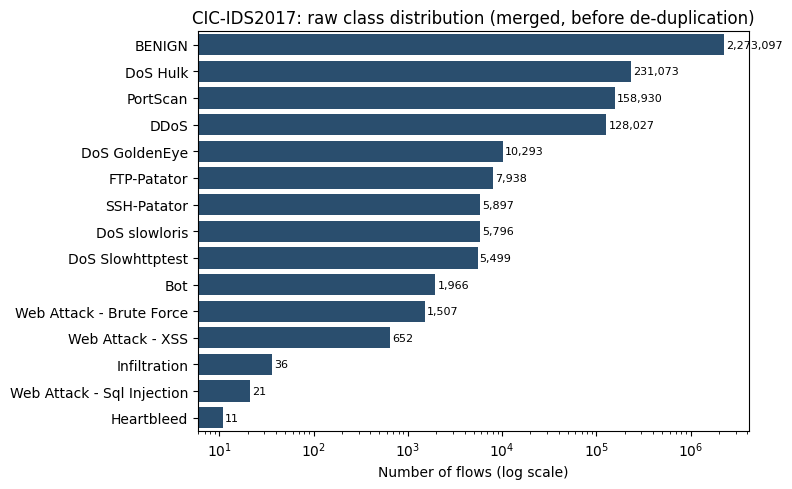

In [ ]:
cnt = df['Label'].value_counts()
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=cnt.values, y=cnt.index, color='#1f4e79')
ax.set_xscale('log')
for p, v in zip(ax.patches, cnt.values):
    ax.text(v * 1.05, p.get_y() + p.get_height() / 2, f"{v:,}", va='center', fontsize=8)
ax.set_xlabel('Number of flows (log scale)'); ax.set_ylabel('')
ax.set_title('CIC-IDS2017: raw class distribution (merged, before de-duplication)')
plt.tight_layout(); save_fig('fig_class_distribution_raw'); plt.show()
RESULTS['raw_class_counts'] = {k: int(v) for k, v in cnt.items()}

In [ ]:
before = df.shape[0]
df = df.drop_duplicates(subset=df.columns.drop('SourceDay')).reset_index(drop=True)
print(f"Duplicate rows removed: {before - df.shape[0]}  ({(before-df.shape[0])/before*100:.2f}% of data)")

Duplicate rows removed: 331200  (11.70% of data)


In [ ]:
invalid_time_cols = ['Flow Duration', 'Flow IAT Mean', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Min', 'Flow Bytes/s', 'Flow Packets/s']
before = df.shape[0]
mask_invalid = (df[invalid_time_cols] < 0).any(axis=1)
print(f"Structurally invalid rows (negative time/rate values): {mask_invalid.sum()} ({mask_invalid.mean()*100:.3f}%)")
df = df.loc[~mask_invalid].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Structurally invalid rows (negative time/rate values): 2881 (0.115%)
Shape after cleaning: (2496662, 79)


### 5. Outlier Pipeline


In [ ]:
def iqr_outlier_count(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((s < lo) | (s > hi)).sum()

report_cols = ['Flow Duration', 'Flow Bytes/s', 'Total Fwd Packets', 'Fwd Packet Length Mean']
iqr_report = {c: iqr_outlier_count(df[c]) for c in report_cols}
print("IQR outlier counts (diagnostic):", iqr_report)

IQR outlier counts (diagnostic): {'Flow Duration': np.int64(465934), 'Flow Bytes/s': np.int64(476246), 'Total Fwd Packets': np.int64(250866), 'Fwd Packet Length Mean': np.int64(177074)}


In [ ]:
z_scores = np.abs(stats.zscore(df[report_cols]))
z_outlier_pct = (z_scores > 3).mean(axis=0) * 100
print("Z-score (>3) outlier % per feature:")
print(pd.Series(z_outlier_pct, index=report_cols))

Z-score (>3) outlier % per feature:
Flow Duration             0.000000
Flow Bytes/s              0.182484
Total Fwd Packets         0.105421
Fwd Packet Length Mean    1.329335
dtype: float64


In [ ]:
benign_mask = df['Label'] == 'BENIGN'
iso = IsolationForest(contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
iso_pred = iso.fit_predict(df.loc[benign_mask, num_cols_raw])
benign_idx = df.loc[benign_mask].index
noisy_benign_idx = benign_idx[iso_pred == -1]

print(f"Flagged {len(noisy_benign_idx)} noisy/likely-mislabeled BENIGN rows "
      f"({len(noisy_benign_idx)/benign_mask.sum()*100:.2f}% of BENIGN)")

df = df.drop(index=noisy_benign_idx).reset_index(drop=True)
print("Shape after outlier handling:", df.shape)

Flagged 20705 noisy/likely-mislabeled BENIGN rows (1.00% of BENIGN)
Shape after outlier handling: (2475957, 79)


### 5.4 Statistical Analysis

In [21]:
df['Binary_Label'] = (df['Label'] != 'BENIGN').astype(int)

key_features = ['Flow Duration', 'Flow Bytes/s', 'Fwd Packet Length Mean',
                 'Bwd Packet Length Mean', 'Flow IAT Mean']

benign_grp = df.loc[df['Binary_Label']==0]
attack_grp = df.loc[df['Binary_Label']==1]

rows = []
for c in key_features:
    t_stat, p_val = stats.ttest_ind(benign_grp[c], attack_grp[c], equal_var=False, nan_policy='omit')
    u_stat, p_mw  = stats.mannwhitneyu(benign_grp[c], attack_grp[c], alternative='two-sided')
    pooled_std = np.sqrt((benign_grp[c].std()**2 + attack_grp[c].std()**2) / 2)
    cohens_d = (attack_grp[c].mean() - benign_grp[c].mean()) / (pooled_std + 1e-9)
    rows.append([c, t_stat, p_val, p_mw, cohens_d])

stat_table = pd.DataFrame(rows, columns=['Feature', 't_stat', 'p_value(t-test)', 'p_value(Mann-Whitney)', "Cohen's d"])
stat_table

,Feature,t_stat,p_value(t-test),p_value(Mann-Whitney),Cohen's d
0,Flow Duration,-375.631042,0.0,0.0,0.704802
1,Flow Bytes/s,74.519051,0.0,0.0,-0.075965
2,Fwd Packet Length Mean,195.980270,0.0,0.0,-0.234297
3,Bwd Packet Length Mean,-619.611633,0.0,0.0,1.308349
4,Flow IAT Mean,-289.609924,0.0,0.0,0.542607


In [ ]:
groups = [g['Flow Duration'].values for _, g in df.groupby('Label') if len(g) > 5]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"ANOVA (Flow Duration across attack types): F={f_stat:.2f}, p={p_anova:.4e}")

df['Is_WellKnown_Port'] = (df['Destination Port'] <= 1023).astype(int)
ct = pd.crosstab(df['Is_WellKnown_Port'], df['Binary_Label'])
chi2, p_chi2, dof, exp = stats.chi2_contingency(ct)
print(f"Chi-square (WellKnownPort vs Attack): chi2={chi2:.2f}, p={p_chi2:.4e}")

ANOVA (Flow Duration across attack types): F=55640.41, p=0.0000e+00
Chi-square (WellKnownPort vs Attack): chi2=3378.89, p=0.0000e+00


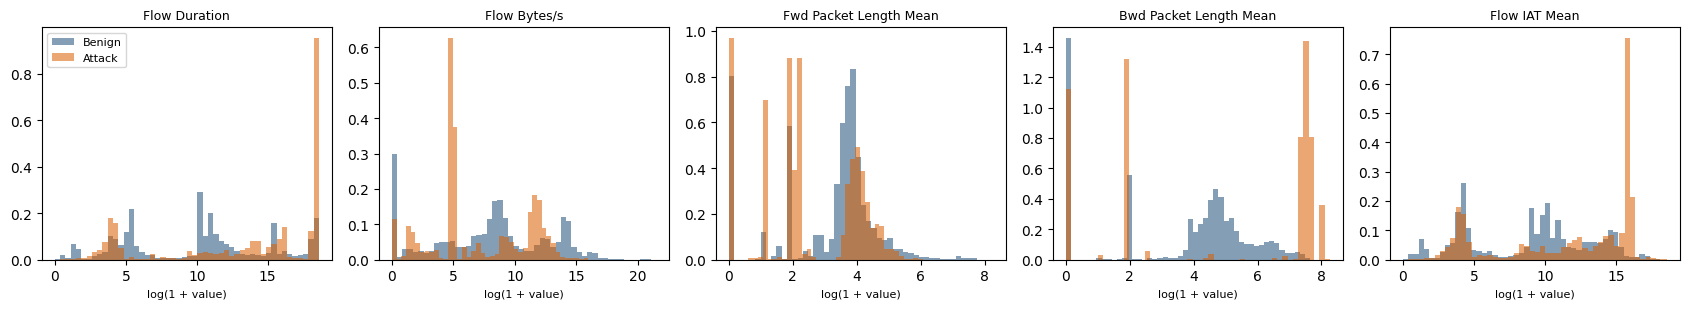

In [ ]:
smp = df.sample(min(100_000, len(df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, len(key_features), figsize=(3.4 * len(key_features), 3.2))
for ax, c in zip(axes, key_features):
    for lab, name, col in [(0, 'Benign', '#1f4e79'), (1, 'Attack', '#d95f02')]:
        v = np.log1p(smp.loc[smp['Binary_Label'] == lab, c].clip(lower=0))
        ax.hist(v, bins=50, alpha=0.55, density=True, label=name, color=col)
    ax.set_title(c, fontsize=9); ax.set_xlabel('log(1 + value)', fontsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout(); save_fig('fig_key_feature_distributions'); plt.show()

### 6. Feature Engineering Pipeline

In [ ]:
df['Fwd_Bwd_Pkt_Ratio']   = df['Total Fwd Packets'] / (df['Total Backward Packets'] + 1)
df['Bytes_per_Packet']    = (df['Total Length of Fwd Packets'] + df['Total Length of Bwd Packets']) / \
                             (df['Total Fwd Packets'] + df['Total Backward Packets'] + 1)
df['Fwd_Bwd_Byte_Ratio']  = df['Total Length of Fwd Packets'] / (df['Total Length of Bwd Packets'] + 1)
df['Flag_Sum']            = df[['FIN Flag Count','SYN Flag Count','RST Flag Count', 'PSH Flag Count','ACK Flag Count','URG Flag Count']].sum(axis=1)

new_feats = ['Fwd_Bwd_Pkt_Ratio','Bytes_per_Packet','Fwd_Bwd_Byte_Ratio','Flag_Sum']
print("New engineered features:", new_feats)
df[new_feats].describe()

New engineered features: ['Fwd_Bwd_Pkt_Ratio', 'Bytes_per_Packet', 'Fwd_Bwd_Byte_Ratio', 'Flag_Sum']


,Fwd_Bwd_Pkt_Ratio,Bytes_per_Packet,Fwd_Bwd_Byte_Ratio,Flag_Sum
count,2.475957e+06,2.475957e+06,2.475957e+06,2.475957e+06
mean,1.160036e+00,1.802360e+02,3.550948e+01,7.904927e-01
std,4.216003e+00,3.142759e+02,8.455242e+02,6.891134e-01
min,6.369427e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.000000e-01,4.500000e+00,5.708865e-02,0.000000e+00
50%,6.666667e-01,5.333333e+01,3.460560e-01,1.000000e+00
75%,1.200000e+00,1.424375e+02,7.542857e-01,1.000000e+00
max,7.410000e+02,3.337143e+03,2.189280e+05,3.000000e+00


### 7. Encoding Pipeline

In [ ]:
le = LabelEncoder()
df['Label_enc'] = le.fit_transform(df['Label'])
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
print(label_map)

sourceday_ohe = pd.get_dummies(df['SourceDay'], prefix='Day')
print("One-hot day columns:", sourceday_ohe.columns.tolist())


{'BENIGN': np.int64(0), 'Bot': np.int64(1), 'DDoS': np.int64(2), 'DoS GoldenEye': np.int64(3), 'DoS Hulk': np.int64(4), 'DoS Slowhttptest': np.int64(5), 'DoS slowloris': np.int64(6), 'FTP-Patator': np.int64(7), 'Heartbleed': np.int64(8), 'Infiltration': np.int64(9), 'PortScan': np.int64(10), 'SSH-Patator': np.int64(11), 'Web Attack - Brute Force': np.int64(12), 'Web Attack - Sql Injection': np.int64(13), 'Web Attack - XSS': np.int64(14)}
One-hot day columns: ['Day_Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Day_Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Day_Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Day_Monday-WorkingHours.pcap_ISCX.csv', 'Day_Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Day_Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Day_Tuesday-WorkingHours.pcap_ISCX.csv', 'Day_Wednesday-workingHours.pcap_ISCX.csv']


### 8. Transformation Pipeline


In [26]:
feature_cols = [c for c in df.columns if c not in ['Label', 'Label_enc', 'Binary_Label', 'SourceDay']]

skewness = df[feature_cols].skew().sort_values(ascending=False)
print("Top 10 most skewed features:")
print(skewness.head(10))
log_candidates = [c for c in feature_cols if (df[c] >= 0).all() and df[c].skew() > 2]
print(f"\n{len(log_candidates)} features selected for log1p transform")
df_transformed = df.copy()
df_transformed[log_candidates] = np.log1p(df_transformed[log_candidates])
print("Skew after log1p (same features):")
print(df_transformed[log_candidates].skew().sort_values(ascending=False).head(10))

Top 10 most skewed features:
Total Length of Fwd Packets    364.269928
Subflow Fwd Bytes              364.269928
act_data_pkt_fwd               237.810135
Fwd URG Flags                  175.916168
CWE Flag Count                 175.916168
Subflow Bwd Bytes              155.976379
Total Length of Bwd Packets    155.976379
Total Fwd Packets              117.587791
Subflow Fwd Packets            117.587791
Total Backward Packets          84.037811
dtype: float64

64 features selected for log1p transform
Skew after log1p (same features):
Fwd URG Flags        175.916168
CWE Flag Count       175.916168
RST Flag Count        60.539978
ECE Flag Count        60.405781
FIN Flag Count         5.258176
Fwd PSH Flags          4.206144
SYN Flag Count         4.206144
Idle Std               3.275165
Active Std             3.252151
Fwd_Bwd_Pkt_Ratio      3.001487
dtype: float32


### 9. (Preview) Feature Selection Pipeline

In [27]:
def select_features_mutual_info(X_train, y_train, k=25):
    mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
    return pd.Series(mi, index=X_train.columns).sort_values(ascending=False).head(k).index.tolist()

def select_features_rfe(X_train, y_train, n_features=25):
    estimator = LogisticRegression(max_iter=200, n_jobs=-1)
    rfe = RFE(estimator, n_features_to_select=n_features, step=5)
    rfe.fit(X_train, y_train)
    return X_train.columns[rfe.support_].tolist()

def select_features_lasso(X_train, y_train, alpha=0.001):
    lasso = Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=5000)
    lasso.fit(X_train, y_train)
    coefs = pd.Series(lasso.coef_, index=X_train.columns)
    return coefs[coefs != 0].index.tolist()

print("Feature selection functions ready (applied in Section 10).")

Feature selection functions ready (applied in Section 10).


#### 10. Train/Test Strategy + Scaling + Feature Selection (leakage-safe, all together)

In [ ]:
X = df_transformed[feature_cols]
y = df_transformed['Label_enc']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Stratified split:", X_train.shape, X_test.shape)

Stratified split: (1980765, 82) (495192, 82)


In [ ]:
imputer_final = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer_final.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test  = pd.DataFrame(imputer_final.transform(X_test),  columns=X_test.columns,  index=X_test.index)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)
print("Scaling done (fit on train only).")

Scaling done (fit on train only).


In [ ]:
selected_features = select_features_mutual_info(X_train_scaled, y_train, k=30)
print(f"Selected {len(selected_features)} features via Mutual Information:")
print(selected_features)

X_train_fs = X_train_scaled[selected_features]
X_test_fs  = X_test_scaled[selected_features]

Selected 30 features via Mutual Information:
['Bytes_per_Packet', 'Average Packet Size', 'Fwd_Bwd_Byte_Ratio', 'Packet Length Std', 'Packet Length Variance', 'Packet Length Mean', 'Total Length of Bwd Packets', 'Subflow Bwd Bytes', 'Avg Bwd Segment Size', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Init_Win_bytes_backward', 'Bwd Packet Length Max', 'Total Length of Fwd Packets', 'Subflow Fwd Bytes', 'Fwd IAT Max', 'Max Packet Length', 'Init_Win_bytes_forward', 'Fwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Std', 'Fwd Packet Length Max', 'Fwd IAT Mean', 'Flow IAT Max', 'Flow Duration', 'Destination Port', 'Avg Fwd Segment Size', 'Fwd Packet Length Mean', 'Flow Bytes/s', 'Flow IAT Std']


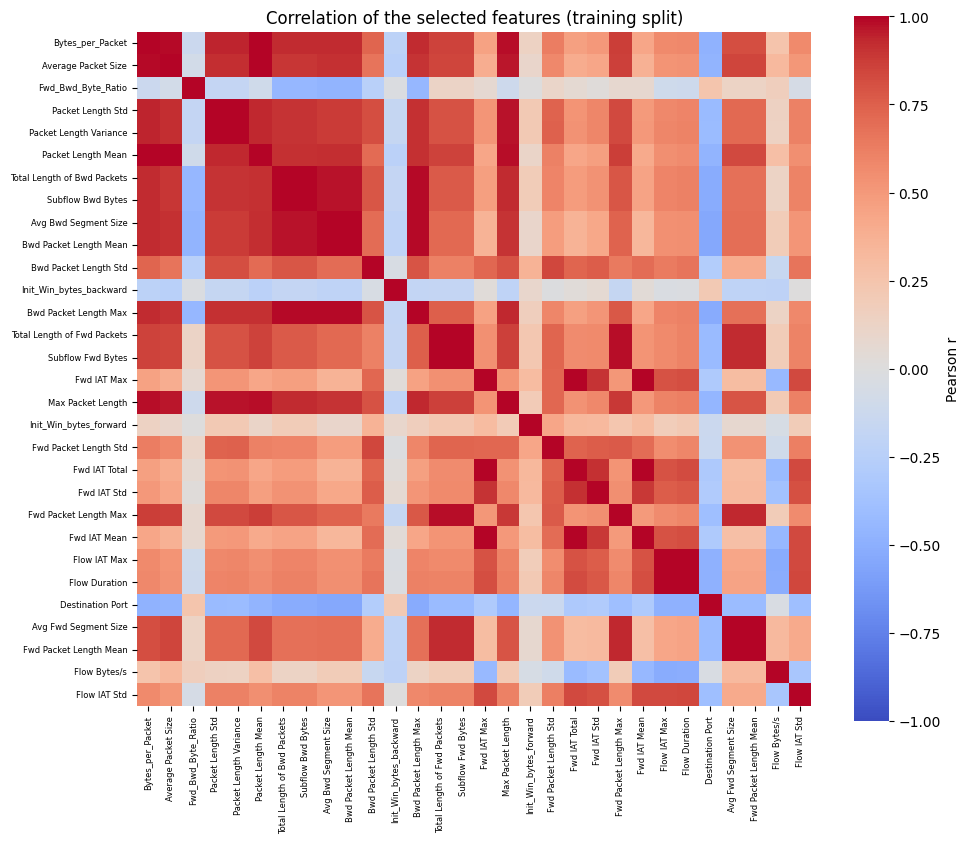

In [ ]:
corr = X_train_fs.sample(min(200_000, len(X_train_fs)), random_state=RANDOM_STATE).corr()
plt.figure(figsize=(10, 8.5))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'label': 'Pearson r'},
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.title('Correlation of the selected features (training split)')
plt.tight_layout(); save_fig('fig_selected_feature_correlation'); plt.show()
RESULTS['selected_features'] = list(selected_features)

### 6.2 Chronological (per-class) validation - alternative split, for the robustness section of the paper


In [ ]:

weekday_order = ['Monday-WorkingHours.pcap_ISCX.csv',
                 'Tuesday-WorkingHours.pcap_ISCX.csv',
                 'Wednesday-workingHours.pcap_ISCX.csv',
                 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
                 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv',
                 'Friday-WorkingHours-Morning.pcap_ISCX.csv',
                 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv',
                 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv']
missing_files = set(df_transformed['SourceDay'].unique()) - set(weekday_order)
assert not missing_files, f"Unexpected SourceDay values: {missing_files}"

day_rank = {f: i for i, f in enumerate(weekday_order)}
order_key = pd.DataFrame({'rank': df_transformed['SourceDay'].map(day_rank).values,
                          'pos': np.arange(len(df_transformed))}, index=df_transformed.index)

chrono_test_idx = []
for cls, grp in order_key.groupby(df_transformed['Label_enc']):
    g = grp.sort_values(['rank', 'pos'])
    n_test = max(1, int(round(0.2 * len(g))))
    chrono_test_idx.extend(g.index[-n_test:])          

test_mask  = df_transformed.index.isin(chrono_test_idx)
train_mask = ~test_mask

X_train_time, y_train_time = X.loc[train_mask], y.loc[train_mask]
X_test_time,  y_test_time  = X.loc[test_mask],  y.loc[test_mask]
print("Chronological split -> train:", X_train_time.shape, "test:", X_test_time.shape)
print("Classes in train:", y_train_time.nunique(), "| classes in test:", y_test_time.nunique())


Chronological split -> train: (1980767, 82) test: (495190, 82)
Classes in train: 15 | classes in test: 15


## 11. Sampling + Imbalance Pipeline

In [33]:
from collections import Counter
print("Class distribution in TRAIN before balancing:")
print(pd.Series(y_train).value_counts().sort_index())

Class distribution in TRAIN before balancing:
Label_enc
0     1640229
1        1562
2      102397
3        8222
4      138153
5        4182
6        4299
7        4743
8           6
9          28
10      72655
11       2574
12       1176
13         17
14        522
Name: count, dtype: int64


In [ ]:

from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN


SMOTE_TARGET    = 10_000
MIN_SMOTE_REAL  = 50
TINY_WEIGHT_CAP = 50.0

def resample_train(X_tr, y_tr, seed=RANDOM_STATE):
    """Apply the v2 resampling policy to a TRAINING partition. Returns X_bal, y_bal, sample_weight, plan, tiny."""
    counts = Counter(np.asarray(y_tr).tolist())
    plan = {c: SMOTE_TARGET for c, n in counts.items() if MIN_SMOTE_REAL <= n < SMOTE_TARGET}
    tiny = {c: n for c, n in counts.items() if n < MIN_SMOTE_REAL}
    if plan:
        X_b, y_b = SMOTE(sampling_strategy=plan, random_state=seed, k_neighbors=5).fit_resample(X_tr, y_tr)
    else:
        X_b, y_b = X_tr, y_tr
    tiny_w = {c: min(TINY_WEIGHT_CAP, SMOTE_TARGET / n) for c, n in tiny.items()}
    w = pd.Series(np.asarray(y_b)).map(tiny_w).fillna(1.0).to_numpy()
    return X_b, y_b, w, plan, tiny

def stratified_fraction(y, frac, seed=RANDOM_STATE, min_per_class=5):
    """Row positions of a stratified subsample that keeps >= min_per_class rows of every class."""
    rs = np.random.RandomState(seed)
    y = np.asarray(y)
    keep = []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        n = min(len(idx), max(min(len(idx), min_per_class), int(np.ceil(frac * len(idx)))))
        keep.extend(rs.choice(idx, n, replace=False))
    return np.array(sorted(keep))

X_train_bal, y_train_bal, w_bal, smote_plan, tiny_classes = resample_train(X_train_fs, y_train)
print(f"SMOTE plan (class -> target size): {smote_plan}")
inv_label_map = {v: k for k, v in label_map.items()}
print("Tiny classes (no synthetic data, capped weights):", {inv_label_map[c]: n for c, n in tiny_classes.items()})
print("Class distribution AFTER resampling (train only):")
print(pd.Series(y_train_bal).value_counts().sort_index())
print("Training rows:", len(y_train_bal), "(v1: 24,603,435)")


SMOTE plan (class -> target size): {7: 10000, 3: 10000, 1: 10000, 5: 10000, 6: 10000, 11: 10000, 14: 10000, 12: 10000}
Tiny classes (no synthetic data, capped weights): {'Heartbleed': 6, 'Web Attack - Sql Injection': 17, 'Infiltration': 28}
Class distribution AFTER resampling (train only):
Label_enc
0     1640229
1       10000
2      102397
3       10000
4      138153
5       10000
6       10000
7       10000
8           6
9          28
10      72655
11      10000
12      10000
13         17
14      10000
Name: count, dtype: int64
Training rows: 2033485 (v1: 24,603,435)


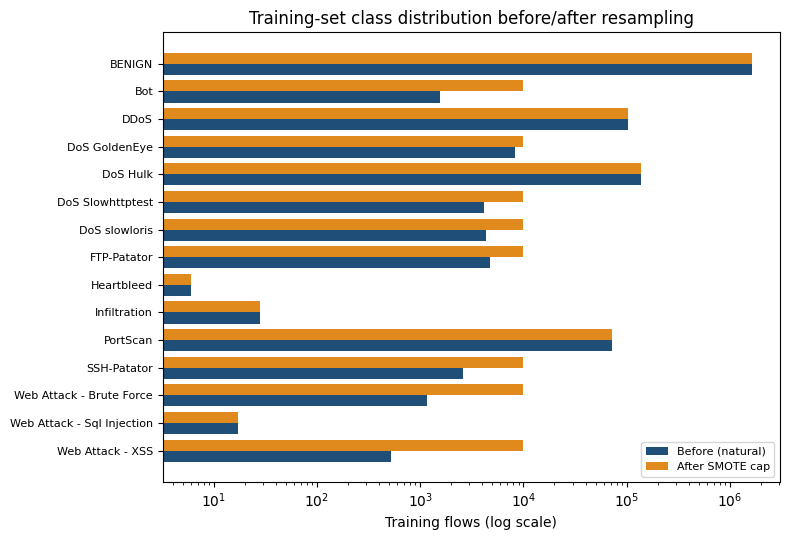

In [ ]:
before = pd.Series(y_train).value_counts().sort_index()
after  = pd.Series(y_train_bal).value_counts().sort_index()
tn = [inv_label_map[i] for i in before.index]
ypos = np.arange(len(tn))
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, before.values, 0.4, label='Before (natural)', color='#1f4e79')
plt.barh(ypos - 0.2, after.reindex(before.index).values, 0.4, label='After SMOTE cap', color='#e08a1e')
plt.yticks(ypos, tn, fontsize=8); plt.gca().invert_yaxis(); plt.xscale('log')
plt.xlabel('Training flows (log scale)'); plt.legend(fontsize=8)
plt.title('Training-set class distribution before/after resampling')
plt.tight_layout(); save_fig('fig_class_distribution_resampling'); plt.show()
RESULTS['train_rows_before'] = int(len(y_train)); RESULTS['train_rows_after_resampling'] = int(len(y_train_bal))

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
classes_ = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes_, y=y_train)
class_weight_dict = dict(zip(classes_, weights))
print("Balanced class weights (alternative to SMOTE):")
print(class_weight_dict)

Balanced class weights (alternative to SMOTE):
{np.int64(0): np.float64(0.08050766082053176), np.int64(1): np.float64(84.53969270166453), np.int64(2): np.float64(1.289598328076018), np.int64(3): np.float64(16.060690829481878), np.int64(4): np.float64(0.9558315780330503), np.int64(5): np.float64(31.576040172166426), np.int64(6): np.float64(30.71667829727844), np.int64(7): np.float64(27.84123972169513), np.int64(8): np.float64(22008.5), np.int64(9): np.float64(4716.107142857143), np.int64(10): np.float64(1.8175073979767393), np.int64(11): np.float64(51.3018648018648), np.int64(12): np.float64(112.28826530612245), np.int64(13): np.float64(7767.705882352941), np.int64(14): np.float64(252.9712643678161)}


## 12. Simulation / Augmentation Pipeline
*(Family 11: Monte Carlo, GAN, VAE, diffusion)*


In [ ]:
'''
from ctgan import CTGAN

rare_classes = [8, 9, 13]  # Heartbleed, Infiltration, Web Attack-SQLi (see label_map above)
for cls in rare_classes:
    cls_data = X_train_fs[y_train == cls]
    ctgan = CTGAN(epochs=300)
    ctgan.fit(cls_data)
    synthetic = ctgan.sample(200)
    # concat synthetic samples with X_train_bal / y_train_bal for that class
'''
print("GAN augmentation stub ready - optional extension for ultra-rare classes.")

GAN augmentation stub ready — optional extension for ultra-rare classes.


## 13. Model Training

In [38]:
import xgboost as xgb

model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(label_map),
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method='hist'
)

model.fit(X_train_bal, y_train_bal, sample_weight=w_bal)
print("Training done.")

Training done.


## 14. Evaluation

In [39]:
y_pred = model.predict(X_test_fs)
y_proba = model.predict_proba(X_test_fs)

inv_label_map = {v: k for k, v in label_map.items()}
target_names = [inv_label_map[i] for i in sorted(inv_label_map)]

print(classification_report(y_test, y_pred, target_names=target_names, digits=4, zero_division=0))

                            precision    recall  f1-score   support

                    BENIGN     0.9998    0.9985    0.9992    410058
                       Bot     0.6966    0.9514    0.8043       391
                      DDoS     0.9998    0.9996    0.9997     25600
             DoS GoldenEye     0.9966    0.9985    0.9976      2055
                  DoS Hulk     0.9978    0.9990    0.9984     34538
          DoS Slowhttptest     0.9923    0.9904    0.9914      1046
             DoS slowloris     0.9944    0.9926    0.9935      1075
               FTP-Patator     1.0000    0.9992    0.9996      1186
                Heartbleed     0.5000    1.0000    0.6667         1
              Infiltration     1.0000    0.5714    0.7273         7
                  PortScan     0.9903    0.9996    0.9949     18164
               SSH-Patator     1.0000    1.0000    1.0000       643
  Web Attack - Brute Force     0.5779    0.6054    0.5914       294
Web Attack - Sql Injection     1.0000    0.2500

### 14.1 Overfitting / Underfitting Check

In [ ]:

from sklearn.metrics import accuracy_score, f1_score

train_pred = model.predict(X_train_fs)
train_acc = accuracy_score(y_train, train_pred)
train_f1  = f1_score(y_train, train_pred, average='macro')

test_acc = accuracy_score(y_test, y_pred)
test_f1  = f1_score(y_test, y_pred, average='macro')

print(f"Train Accuracy: {train_acc:.4f}   |   Test Accuracy: {test_acc:.4f}   |   Gap: {train_acc-test_acc:.4f}")
print(f"Train Macro-F1: {train_f1:.4f}   |   Test Macro-F1: {test_f1:.4f}   |   Gap: {train_f1-test_f1:.4f}")
print()
print("Rule of thumb: gap > 0.05-0.10 -> investigate overfitting. Both numbers are on natural (imbalanced) data.")
RESULTS['train_test_gap'] = dict(train_acc=float(train_acc), test_acc=float(test_acc), train_macro_f1=float(train_f1), test_macro_f1=float(test_f1))


Train Accuracy: 0.9984   |   Test Accuracy: 0.9982   |   Gap: 0.0002
Train Macro-F1: 0.9238   |   Test Macro-F1: 0.8336   |   Gap: 0.0902

Rule of thumb: gap > 0.05-0.10 -> investigate overfitting. Both numbers are on natural (imbalanced) data.


In [41]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_model = xgb.XGBClassifier(**model.get_params())

cv_scores = cross_val_score(cv_model, X_train_fs, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
print("5-fold CV Macro-F1 scores:", np.round(cv_scores, 4))
print(f"Mean: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")
print()
print("Small std (e.g. < 0.02) across folds -> stable model, not just lucky on one split.")
print("If CV mean is much lower than the single test_f1 above -> the single split was optimistic; report the CV mean instead.")

5-fold CV Macro-F1 scores: [0.8764 0.8981 0.8456 0.8681 0.8623]
Mean: 0.8701  |  Std: 0.0173

Small std (e.g. < 0.02) across folds -> stable model, not just lucky on one split.
If CV mean is much lower than the single test_f1 above -> the single split was optimistic; report the CV mean instead.


fraction 0.10: n_train=  168,380  train macro-F1=0.9575  validation macro-F1=0.8350
fraction 0.25: n_train=  420,922  train macro-F1=0.9501  validation macro-F1=0.8417
fraction 0.50: n_train=  841,830  train macro-F1=0.9332  validation macro-F1=0.8729
fraction 0.75: n_train=1,262,743  train macro-F1=0.9279  validation macro-F1=0.8778
fraction 1.00: n_train=1,683,650  train macro-F1=0.9232  validation macro-F1=0.8742


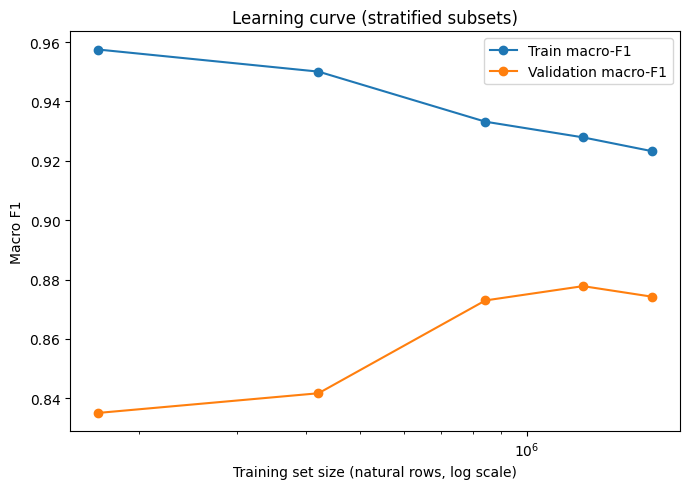

Interpretation:
 - Curves converging close together, both HIGH  -> good fit
 - Big persistent gap (train high, val low)      -> overfitting (try: lower max_depth, more regularization, fewer features)
 - Both curves LOW and flat                       -> underfitting (try: more features, higher max_depth, more estimators)


In [42]:
X_lc_tr, X_lc_val, y_lc_tr, y_lc_val = train_test_split(X_train_fs, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
lc_rows = []
for fr in fracs:
    pos = stratified_fraction(y_lc_tr, fr)
    Xs, ys = X_lc_tr.iloc[pos], y_lc_tr.iloc[pos]
    Xb, yb, wb, _, _ = resample_train(Xs, ys)
    m = xgb.XGBClassifier(**model.get_params())
    m.fit(Xb, yb, sample_weight=wb)
    f_tr  = f1_score(ys, m.predict(Xs), average='macro')
    f_val = f1_score(y_lc_val, m.predict(X_lc_val), average='macro')
    lc_rows.append((len(ys), f_tr, f_val))
    print(f"fraction {fr:.2f}: n_train={len(ys):>9,}  train macro-F1={f_tr:.4f}  validation macro-F1={f_val:.4f}")
lc = pd.DataFrame(lc_rows, columns=['n_train', 'train_f1', 'val_f1'])

plt.figure(figsize=(7, 5))
plt.plot(lc['n_train'], lc['train_f1'], 'o-', label='Train macro-F1')
plt.plot(lc['n_train'], lc['val_f1'], 'o-', label='Validation macro-F1')
plt.xscale('log'); plt.xlabel('Training set size (natural rows, log scale)'); plt.ylabel('Macro F1')
plt.title('Learning curve (stratified subsets)')
plt.legend(); plt.tight_layout(); save_fig('fig_learning_curve'); plt.show()
lc.to_csv(os.path.join(FIG_DIR, 'learning_curve.csv'), index=False)
RESULTS['learning_curve'] = lc.to_dict(orient='list')

print("Interpretation:")
print(" - Curves converging close together, both HIGH  -> good fit")
print(" - Big persistent gap (train high, val low)      -> overfitting (try: lower max_depth, more regularization, fewer features)")
print(" - Both curves LOW and flat                       -> underfitting (try: more features, higher max_depth, more estimators)")


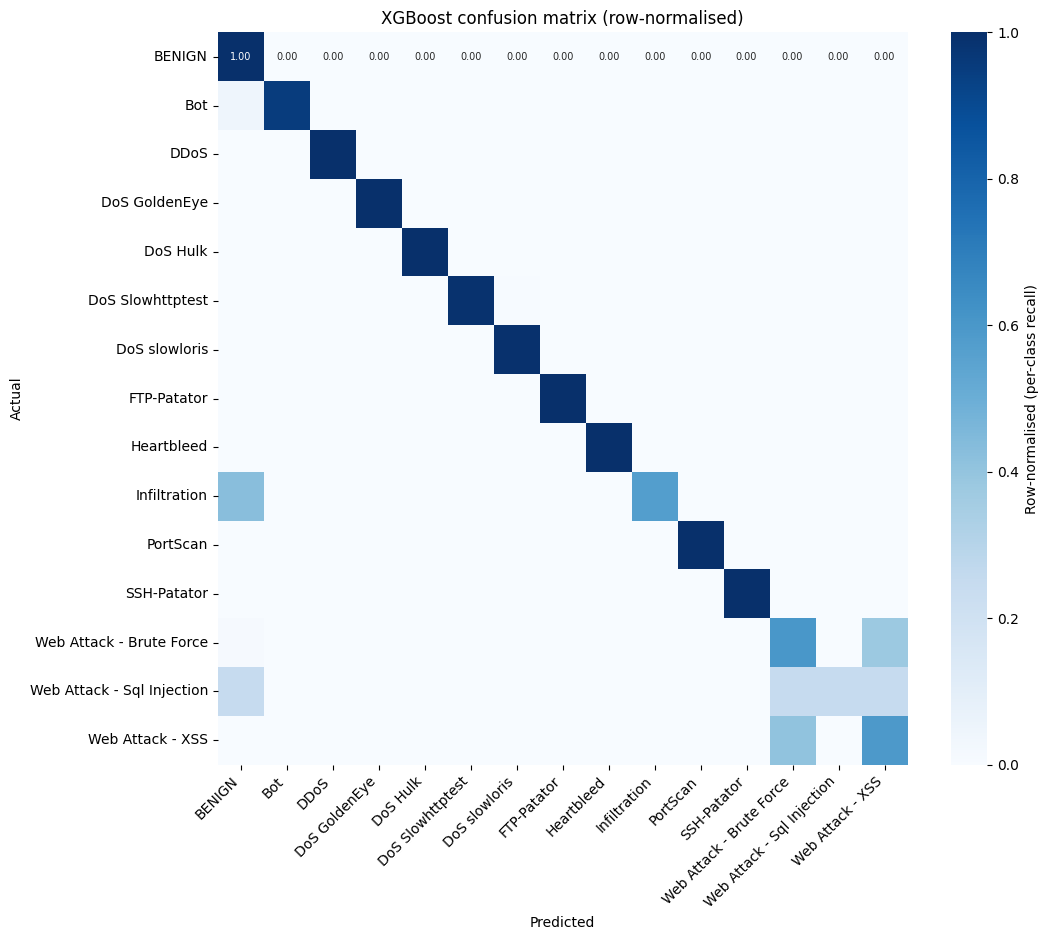

BENIGN flows misclassified: 619 of 410058
BENIGN                      409439
Bot                            162
DDoS                             3
DoS Hulk                        64
DoS Slowhttptest                 4
DoS slowloris                    1
Heartbleed                       1
PortScan                       178
Web Attack - Brute Force        75
Web Attack - XSS               131


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(target_names))))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=target_names, yticklabels=target_names,
            ax=ax, annot_kws={'size': 7}, cbar_kws={'label': 'Row-normalised (per-class recall)'})
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('XGBoost confusion matrix (row-normalised)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); save_fig('fig_confusion_matrix_xgb'); plt.show()
pd.DataFrame(cm, index=target_names, columns=target_names).to_csv(os.path.join(FIG_DIR, 'confusion_matrix_counts_xgb.csv'))
benign_row = pd.Series(cm[label_map['BENIGN']], index=target_names)
print("BENIGN flows misclassified:", int(benign_row.sum() - benign_row['BENIGN']), "of", int(benign_row.sum()))
print(benign_row[benign_row > 0].to_string())


In [ ]:
try:
    macro_auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')
    print(f"Macro ROC-AUC (OvR): {macro_auc:.4f}")
except Exception as e:
    print("ROC-AUC computation note:", e)

Macro ROC-AUC (OvR): 0.9996


### 14.2 Binary view (Benign vs Attack) - the most comparable number in the IDS literature

Binary (Benign vs Attack) XGBoost: {'accuracy': 0.998613, 'precision': 0.992776, 'recall': 0.999201, 'f1': 0.995978, 'roc_auc': 0.999971, 'pr_auc': 0.999862, 'false_alarm_rate': 0.00151, 'miss_rate': 0.000799, 'TP': 85066, 'FP': 619, 'TN': 409439, 'FN': 68}


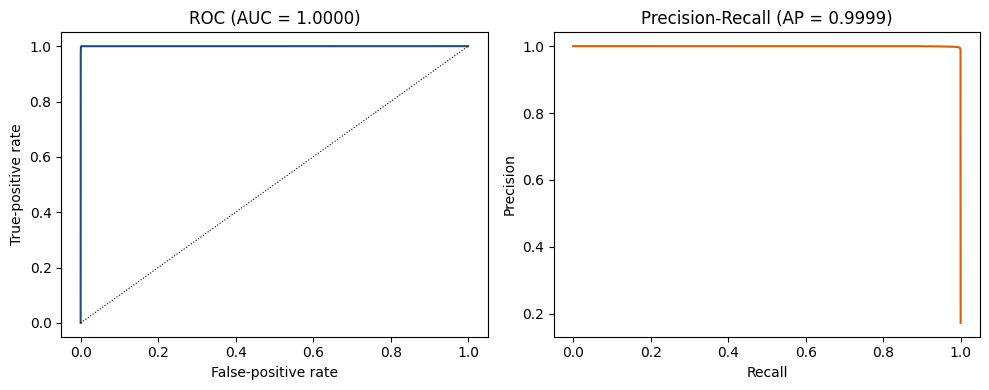

In [45]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, precision_score, recall_score

BEN = label_map['BENIGN']
y_test_bin = (np.asarray(y_test) != BEN).astype(int)
y_pred_bin = (np.asarray(y_pred) != BEN).astype(int)
p_attack   = 1.0 - y_proba[:, BEN]

tn_, fp_, fn_, tp_ = confusion_matrix(y_test_bin, y_pred_bin).ravel()
bin_metrics = dict(accuracy=float(accuracy_score(y_test_bin, y_pred_bin)),
                   precision=float(precision_score(y_test_bin, y_pred_bin)),
                   recall=float(recall_score(y_test_bin, y_pred_bin)),
                   f1=float(f1_score(y_test_bin, y_pred_bin)),
                   roc_auc=float(roc_auc_score(y_test_bin, p_attack)),
                   pr_auc=float(average_precision_score(y_test_bin, p_attack)),
                   false_alarm_rate=float(fp_ / (fp_ + tn_)), miss_rate=float(fn_ / (fn_ + tp_)),
                   TP=int(tp_), FP=int(fp_), TN=int(tn_), FN=int(fn_))
print("Binary (Benign vs Attack) XGBoost:", {k: round(v, 6) if isinstance(v, float) else v for k, v in bin_metrics.items()})
RESULTS['binary_xgb'] = bin_metrics

fpr, tpr, _ = roc_curve(y_test_bin, p_attack)
prec, rec, _ = precision_recall_curve(y_test_bin, p_attack)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, color='#1f4e79'); ax[0].plot([0, 1], [0, 1], 'k:', lw=0.8)
ax[0].set_xlabel('False-positive rate'); ax[0].set_ylabel('True-positive rate'); ax[0].set_title(f"ROC (AUC = {bin_metrics['roc_auc']:.4f})")
ax[1].plot(rec, prec, color='#d95f02'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title(f"Precision-Recall (AP = {bin_metrics['pr_auc']:.4f})")
plt.tight_layout(); save_fig('fig_binary_roc_pr'); plt.show()

### 15. Explainability Layer (SHAP) - the "X" in XThreat

In [46]:
import shap

explainer = shap.TreeExplainer(model)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(X_test_fs.index, size=min(2000, len(X_test_fs)), replace=False)
X_shap_sample = X_test_fs.loc[sample_idx]

shap_values = explainer.shap_values(X_shap_sample)
print("SHAP values computed. Shape:", np.array(shap_values).shape)

SHAP values computed. Shape: (2000, 30, 15)


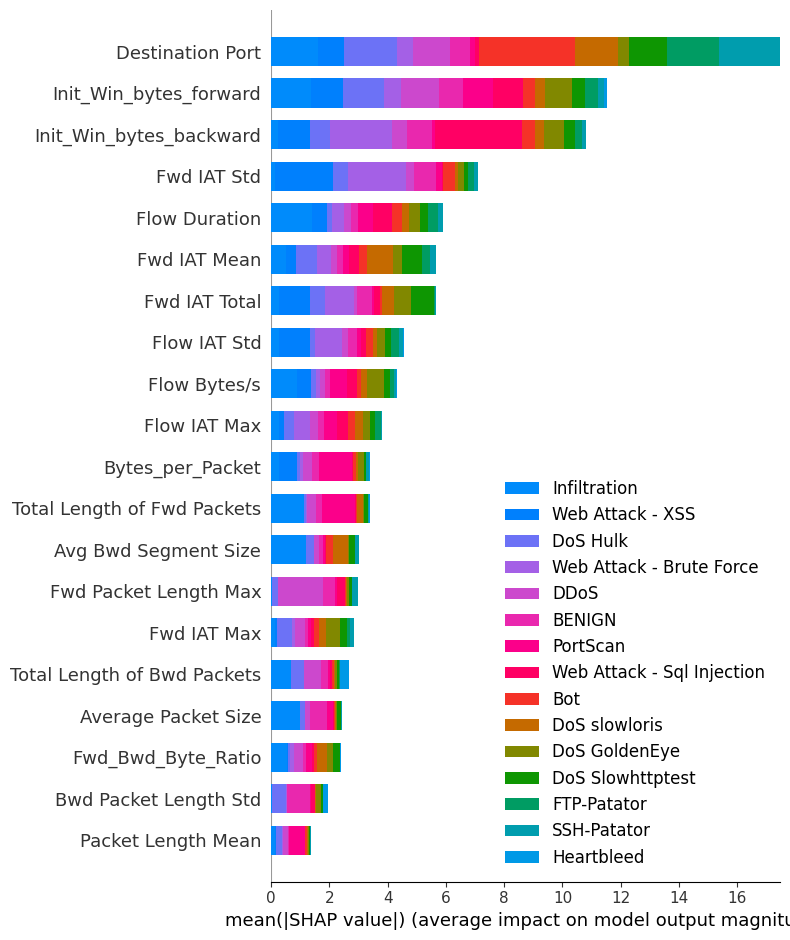

In [ ]:

shap.summary_plot(shap_values, X_shap_sample, feature_names=selected_features, class_names=target_names, plot_type='bar', show=False)
save_fig('fig_shap_global_stacked'); plt.show()


#### 15.1 Global importance of the *predicted* class (clearer than the stacked multi-class bar)

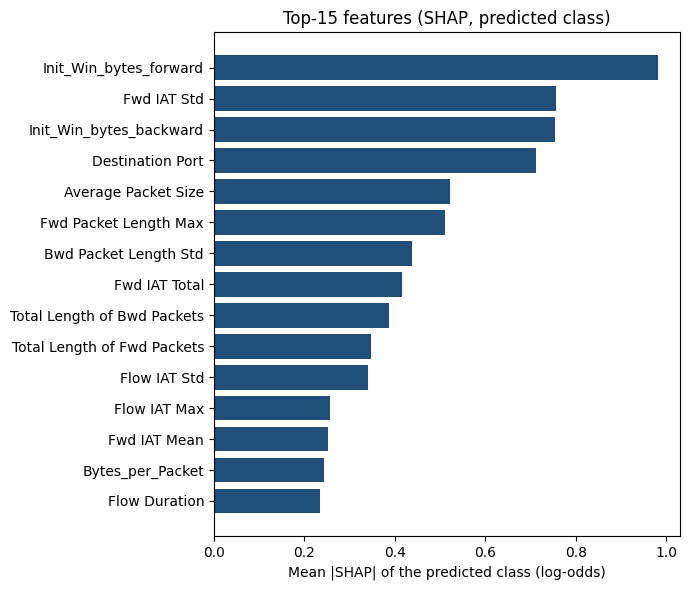

,Predicted class,n (sample),Top-1,Top-2,Top-3
0,BENIGN,1606,Init_Win_bytes_forward (0.99),Init_Win_bytes_backward (0.79),Destination Port (0.73)
1,Bot,2,Flow Bytes/s (2.62),Avg Bwd Segment Size (2.56),Flow Duration (2.28)
2,DDoS,114,Fwd Packet Length Max (1.98),Total Length of Bwd Packets (1.34),Total Length of Fwd Packets (1.04)
3,DoS GoldenEye,8,Total Length of Bwd Packets (5.19),Bwd Packet Length Std (2.93),Init_Win_bytes_forward (1.71)
4,DoS Hulk,164,Fwd IAT Std (2.01),Bwd Packet Length Std (1.79),Fwd IAT Mean (1.11)
5,DoS Slowhttptest,5,Max Packet Length (4.93),Flow IAT Std (4.68),Fwd IAT Mean (0.61)
6,DoS slowloris,6,Fwd_Bwd_Byte_Ratio (3.81),Flow Bytes/s (2.06),Flow IAT Std (1.94)
7,FTP-Patator,4,Destination Port (14.67),Avg Fwd Segment Size (0.97),Total Length of Bwd Packets (0.76)
8,PortScan,85,Total Length of Fwd Packets (2.44),Init_Win_bytes_forward (1.49),Average Packet Size (0.65)
9,SSH-Patator,2,Destination Port (11.92),Fwd Packet Length Max (2.48),Flow Bytes/s (1.63)


In [ ]:
shap_arr = np.stack(shap_values, axis=-1) if isinstance(shap_values, list) else np.asarray(shap_values)   
pred_cls_sample = model.predict(X_shap_sample)
pc_abs = np.array([np.abs(shap_arr[i, :, pred_cls_sample[i]]) for i in range(len(pred_cls_sample))])   
imp_pc = pd.Series(pc_abs.mean(axis=0), index=selected_features).sort_values()

plt.figure(figsize=(7, 6))
plt.barh(imp_pc.tail(15).index, imp_pc.tail(15).values, color='#1f4e79')
plt.xlabel('Mean |SHAP| of the predicted class (log-odds)'); plt.title('Top-15 features (SHAP, predicted class)')
plt.tight_layout(); save_fig('fig_shap_global_predicted_class'); plt.show()
RESULTS['shap_global_top15'] = imp_pc.tail(15).iloc[::-1].to_dict()

rows = []
for c in np.unique(pred_cls_sample):
    m = pred_cls_sample == c
    s = pd.Series(pc_abs[m].mean(axis=0), index=selected_features).sort_values(ascending=False).head(3)
    rows.append([inv_label_map[c], int(m.sum())] + [f"{k} ({v:.2f})" for k, v in s.items()])
class_top_feats = pd.DataFrame(rows, columns=['Predicted class', 'n (sample)', 'Top-1', 'Top-2', 'Top-3'])
class_top_feats.to_csv(os.path.join(FIG_DIR, 'shap_top3_per_class.csv'), index=False)
class_top_feats

Explaining instance 1529854 — predicted class: FTP-Patator
Confidence: 1.0000


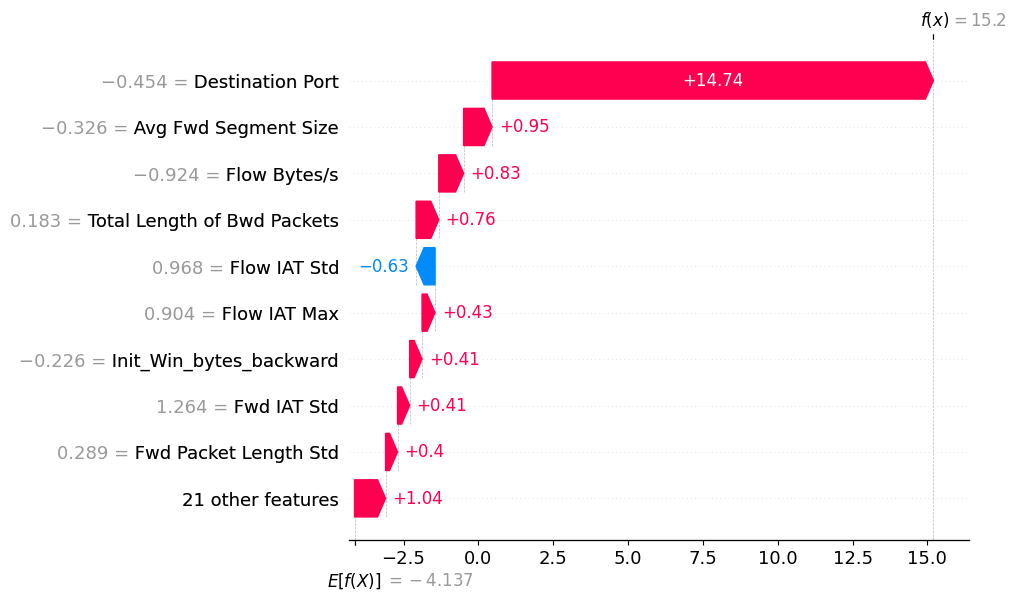

In [ ]:
def get_class_shap_row(shap_values, row_pos, class_idx):
    if isinstance(shap_values, list):
        return shap_values[class_idx][row_pos]
    arr = np.asarray(shap_values)
    if arr.ndim == 3:
        return arr[row_pos, :, class_idx]
    return arr[row_pos]

def get_expected_value(explainer, class_idx):
    ev = explainer.expected_value
    if hasattr(ev, '__len__'):
        return ev[class_idx]
    return ev

brute_force_class = label_map.get('FTP-Patator', label_map.get('SSH-Patator'))
y_pred_sample = model.predict(X_shap_sample)
candidates = X_shap_sample.index[y_pred_sample == brute_force_class]

if len(candidates) > 0:
    idx = candidates[0]
    pos = X_shap_sample.index.get_loc(idx)
    print(f"Explaining instance {idx} — predicted class: {inv_label_map[model.predict(X_shap_sample.loc[[idx]])[0]]}")
    print(f"Confidence: {model.predict_proba(X_shap_sample.loc[[idx]]).max():.4f}")

    sv_row = get_class_shap_row(shap_values, pos, brute_force_class)
    ev = get_expected_value(explainer, brute_force_class)

    expl = shap.Explanation(values=sv_row, base_values=ev, data=X_shap_sample.loc[idx].values, feature_names=list(selected_features))
    shap.plots.waterfall(expl, max_display=10, show=False)
    save_fig('fig_shap_waterfall_' + inv_label_map[brute_force_class].replace(' ', '_'))
    plt.show()
else:
    print("No Brute-Force prediction in this sample — try a larger sample_idx or a different class.")

### 16. Second Model: LightGBM (multi-model comparison)



In [50]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split as tts

print("X_train_bal dtypes unique:", X_train_bal.dtypes.unique())
print("Any NaN in X_train_bal:", X_train_bal.isnull().values.any())
print("y_train_bal unique classes:", np.unique(y_train_bal))
print("X_train_bal shape:", X_train_bal.shape)

X_tr_lgb, X_val_lgb, y_tr_lgb, y_val_lgb, w_tr_lgb, w_val_lgb = tts(
    X_train_bal, y_train_bal, w_bal, test_size=0.1, stratify=y_train_bal, random_state=RANDOM_STATE
)

lgbm_model = lgb.LGBMClassifier(
    n_estimators=500,
    num_leaves=63,
    max_depth=-1,
    learning_rate=0.05,
    min_child_samples=50,
    reg_alpha=0.1,
    reg_lambda=0.1,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    objective='multiclass',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(
    X_tr_lgb, y_tr_lgb,
    sample_weight=w_tr_lgb,
    eval_set=[(X_val_lgb, y_val_lgb)],
    eval_sample_weight=[w_val_lgb],
    eval_metric='multi_logloss',
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=True)]
)

y_pred_lgbm = lgbm_model.predict(X_test_fs)

print("=== LightGBM ===")
print(classification_report(y_test, y_pred_lgbm, target_names=target_names, digits=4, zero_division=0))

X_train_bal dtypes unique: [dtype('float64')]
Any NaN in X_train_bal: False
y_train_bal unique classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
X_train_bal shape: (2033485, 30)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[186]	valid_0's multi_logloss: 0.0189135
=== LightGBM ===
                            precision    recall  f1-score   support

                    BENIGN     0.9998    0.9982    0.9990    410058
                       Bot     0.6923    0.9668    0.8068       391
                      DDoS     0.9998    0.9995    0.9996     25600
             DoS GoldenEye     0.9966    0.9946    0.9956      2055
                  DoS Hulk     0.9977    0.9989    0.9983     34538
          DoS Slowhttptest     0.9895    0.9933    0.9914      1046
             DoS slowloris     0.9963    0.9926    0.9944      1075
               FTP-Patator     1.0000    1.0000    1.0000      1186
                Heartbleed     0.5000    1.0000  

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

def model_summary(y_true, y_pred, name):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return {'Model': name, 'Accuracy': acc, 'Macro-P': p, 'Macro-R': r, 'Macro-F1': f1}

comparison = pd.DataFrame([
    model_summary(y_test, y_pred, 'XGBoost'),
    model_summary(y_test, y_pred_lgbm, 'LightGBM'),
])
comparison

,Model,Accuracy,Macro-P,Macro-R,Macro-F1
0,XGBoost,0.998211,0.865603,0.863200,0.833588
1,LightGBM,0.997956,0.747348,0.848186,0.782088


### 16.1 Baselines (Random Forest, Logistic Regression) and per-class comparison

                         Model  Accuracy  Macro-P  Macro-R  Macro-F1
                       XGBoost    0.9982   0.8656   0.8632    0.8336
                      LightGBM    0.9980   0.7473   0.8482    0.7821
      Random Forest (baseline)    0.9981   0.8551   0.8197    0.8224
Logistic Regression (baseline)    0.9824   0.5440   0.6304    0.5614
Baseline fit+predict time: RF 27s, LR 49s (trained on 500,007 rows)


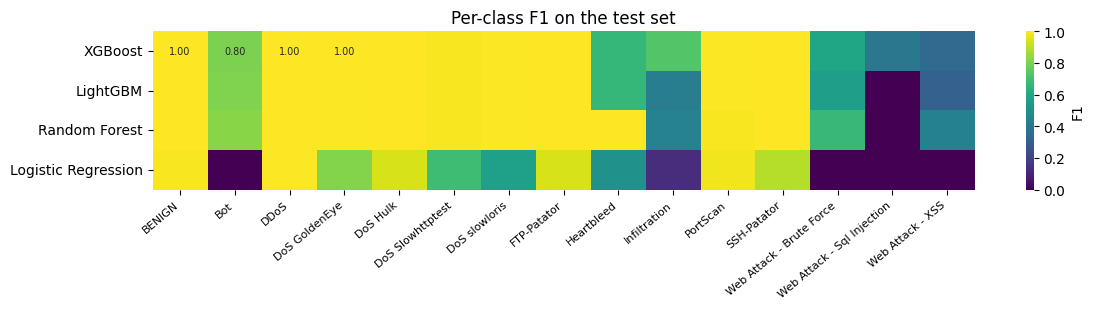

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

K = len(target_names); ALL = list(range(K))
def per_class_f1(y_true, y_hat):
    return f1_score(y_true, y_hat, labels=ALL, average=None, zero_division=0)

BASELINE_N = 500_000
sub = stratified_fraction(y_train_bal, min(1.0, BASELINE_N / len(y_train_bal)))
Xb_sub, yb_sub, wb_sub = X_train_bal.iloc[sub], np.asarray(y_train_bal)[sub], w_bal[sub]

t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xb_sub, yb_sub, sample_weight=wb_sub)
y_pred_rf = rf.predict(X_test_fs); t_rf = time.time() - t0

t0 = time.time()
lr = LogisticRegression(max_iter=300)
lr.fit(Xb_sub, yb_sub, sample_weight=wb_sub)
y_pred_lr = lr.predict(X_test_fs); t_lr = time.time() - t0

comparison_all = pd.DataFrame([
    model_summary(y_test, y_pred, 'XGBoost'),
    model_summary(y_test, y_pred_lgbm, 'LightGBM'),
    model_summary(y_test, y_pred_rf, 'Random Forest (baseline)'),
    model_summary(y_test, y_pred_lr, 'Logistic Regression (baseline)'),
])
print(comparison_all.round(4).to_string(index=False))
print(f"Baseline fit+predict time: RF {t_rf:.0f}s, LR {t_lr:.0f}s (trained on {len(sub):,} rows)")
comparison_all.to_csv(os.path.join(FIG_DIR, 'model_comparison.csv'), index=False)
RESULTS['model_comparison'] = comparison_all.to_dict(orient='records')

f1_table = pd.DataFrame({'XGBoost': per_class_f1(y_test, y_pred), 'LightGBM': per_class_f1(y_test, y_pred_lgbm), 'Random Forest': per_class_f1(y_test, y_pred_rf), 'Logistic Regression': per_class_f1(y_test, y_pred_lr)}, index=target_names).T
plt.figure(figsize=(12, 3.2))
sns.heatmap(f1_table, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, annot_kws={'size': 7}, cbar_kws={'label': 'F1'})
plt.xticks(rotation=40, ha='right', fontsize=8); plt.title('Per-class F1 on the test set')
plt.tight_layout(); save_fig('fig_per_class_f1_heatmap'); plt.show()
f1_table.T.to_csv(os.path.join(FIG_DIR, 'per_class_f1_all_models.csv'))

### 16.2 Ablation: does the model depend on the port feature?

                                             Setting  Accuracy  Macro-P  Macro-R  Macro-F1
Previous run (v1: with Day_Index, SMOTE to majority)    0.9994   0.9327   0.8951    0.8973
                           XGBoost v2 (no Day_Index)    0.9982   0.8656   0.8632    0.8336
                    XGBoost v2 without port features    0.9979   0.8585   0.8724    0.8540


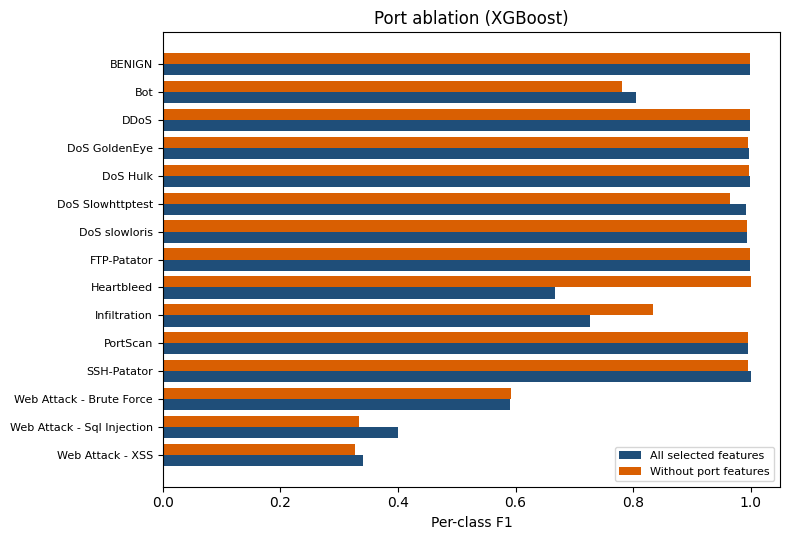

In [ ]:
no_port_cols = [c for c in selected_features if c not in ('Destination Port', 'Is_WellKnown_Port')]
m_np = xgb.XGBClassifier(**model.get_params())
m_np.fit(X_train_bal[no_port_cols], y_train_bal, sample_weight=w_bal)
y_pred_np = m_np.predict(X_test_fs[no_port_cols])
def _row(setting, d):
    return {'Setting': setting, 'Accuracy': d['Accuracy'], 'Macro-P': d['Macro-P'], 'Macro-R': d['Macro-R'], 'Macro-F1': d['Macro-F1']}
PREVIOUS_RUN_WITH_DAY_INDEX = {'Accuracy': 0.999394, 'Macro-P': 0.932745, 'Macro-R': 0.895109, 'Macro-F1': 0.897327}   
ab = pd.DataFrame([
    _row('Previous run (v1: with Day_Index, SMOTE to majority)', PREVIOUS_RUN_WITH_DAY_INDEX),
    _row('XGBoost v2 (no Day_Index)', model_summary(y_test, y_pred, 'x')),
    _row('XGBoost v2 without port features', model_summary(y_test, y_pred_np, 'x')),
])
print(ab.round(4).to_string(index=False))
ab.to_csv(os.path.join(FIG_DIR, 'ablation_port.csv'), index=False)
RESULTS['ablation_port'] = ab.to_dict(orient='records')
f1_np = per_class_f1(y_test, y_pred_np); f1_main = per_class_f1(y_test, y_pred)
ypos = np.arange(K)
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, f1_main, 0.4, label='All selected features', color='#1f4e79')
plt.barh(ypos - 0.2, f1_np, 0.4, label='Without port features', color='#d95f02')
plt.yticks(ypos, target_names, fontsize=8); plt.gca().invert_yaxis(); plt.xlabel('Per-class F1'); plt.legend(fontsize=8)
plt.title('Port ablation (XGBoost)')
plt.tight_layout(); save_fig('fig_port_ablation'); plt.show()

### 16.3 Per-class chronological evaluation (uses the split defined in Section 6.2)

{'Model': 'XGBoost (chronological split)', 'Accuracy': 0.9635, 'Macro-P': 0.7102, 'Macro-R': 0.8022, 'Macro-F1': 0.7232}
                            precision    recall  f1-score   support

                    BENIGN     0.9971    0.9625    0.9795    410057
                       Bot     0.0710    0.9719    0.1323       391
                      DDoS     0.7173    0.9979    0.8346     25599
             DoS GoldenEye     0.9426    0.9985    0.9698      2055
                  DoS Hulk     0.9976    0.9407    0.9683     34538
          DoS Slowhttptest     0.7898    0.9914    0.8792      1046
             DoS slowloris     0.9906    0.7833    0.8748      1075
               FTP-Patator     1.0000    0.9781    0.9889      1186
                Heartbleed     0.0000    0.0000    0.0000         1
              Infiltration     0.7143    0.7143    0.7143         7
                  PortScan     0.9474    0.9954    0.9708     18164
               SSH-Patator     0.9952    0.9751    0.9851     

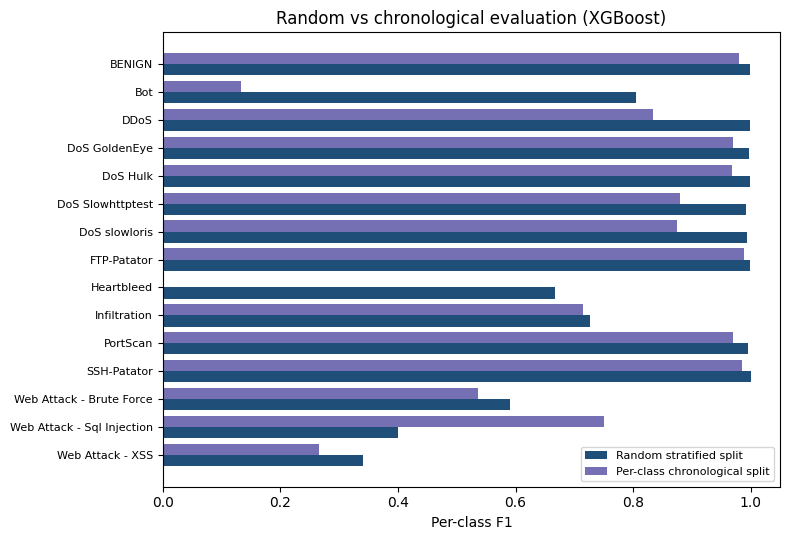

In [ ]:
imp_c = SimpleImputer(strategy='median').fit(X_train_time)
sc_c  = StandardScaler().fit(imp_c.transform(X_train_time))
def prep_c(Xd):
    return pd.DataFrame(sc_c.transform(imp_c.transform(Xd)), columns=Xd.columns, index=Xd.index)
Xc_tr, Xc_te = prep_c(X_train_time), prep_c(X_test_time)

sub_mi = stratified_fraction(y_train_time, min(1.0, 300_000 / len(y_train_time)))
mi = mutual_info_classif(Xc_tr.iloc[sub_mi], y_train_time.iloc[sub_mi], random_state=RANDOM_STATE)
sel_c = pd.Series(mi, index=Xc_tr.columns).sort_values(ascending=False).head(30).index.tolist()

Xc_bal, yc_bal, wc_bal, _, _ = resample_train(Xc_tr[sel_c], y_train_time)
m_c = xgb.XGBClassifier(**model.get_params())
m_c.fit(Xc_bal, yc_bal, sample_weight=wc_bal)
y_pred_c = m_c.predict(Xc_te[sel_c])

chrono = model_summary(y_test_time, y_pred_c, 'XGBoost (chronological split)')
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in chrono.items()})
print(classification_report(y_test_time, y_pred_c, labels=ALL, target_names=target_names, digits=4, zero_division=0))
RESULTS['chronological_xgb'] = chrono

f1_chr = per_class_f1(y_test_time, y_pred_c)
plt.figure(figsize=(8, 5.5))
plt.barh(ypos + 0.2, f1_main, 0.4, label='Random stratified split', color='#1f4e79')
plt.barh(ypos - 0.2, f1_chr, 0.4, label='Per-class chronological split', color='#7570b3')
plt.yticks(ypos, target_names, fontsize=8); plt.gca().invert_yaxis(); plt.xlabel('Per-class F1'); plt.legend(fontsize=8)
plt.title('Random vs chronological evaluation (XGBoost)')
plt.tight_layout(); save_fig('fig_random_vs_chronological'); plt.show()

In [ ]:
'''
# Transformer sketch (PyTorch), operating on a single flow's features as a token sequence:
import torch, torch.nn as nn

class FlowTransformer(nn.Module):
    def __init__(self, n_features, d_model=64, n_heads=4, n_layers=2, n_classes=15):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.classifier = nn.Linear(d_model * n_features, n_classes)

    def forward(self, x):                      # x: (batch, n_features)
        x = x.unsqueeze(-1)                     # (batch, n_features, 1) -> treat each feature as a "token"
        x = self.embed(x)                       # (batch, n_features, d_model)
        x = self.encoder(x)
        x = x.flatten(1)
        return self.classifier(x)

# GNN sketch (PyTorch Geometric), operating on a host-interaction graph built from SourceDay + IP-like grouping:
# from torch_geometric.nn import GCNConv
# class FlowGCN(nn.Module):
#     def __init__(self, n_features, hidden=64, n_classes=15):
#         super().__init__()
#         self.conv1 = GCNConv(n_features, hidden)
#         self.conv2 = GCNConv(hidden, n_classes)
#     def forward(self, x, edge_index):
#         x = self.conv1(x, edge_index).relu()
#         return self.conv2(x, edge_index)
'''
print("Transformer/GNN stubs ready — extension point for later novelty work.")

Transformer/GNN stubs ready — extension point for later novelty work.


### 17. LIME Explainability

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_fs.values,
    feature_names=selected_features,
    class_names=target_names,
    mode='classification',
    random_state=RANDOM_STATE
)

lime_idx = idx
lime_instance = X_test_fs.loc[lime_idx].values

lime_exp = lime_explainer.explain_instance(
    lime_instance,
    model.predict_proba,
    num_features=10,
    top_labels=1
)

lime_exp.save_to_file("lime_explanation.html")

print("LIME explanation saved to: lime_explanation.html")

LIME explanation saved to: lime_explanation.html


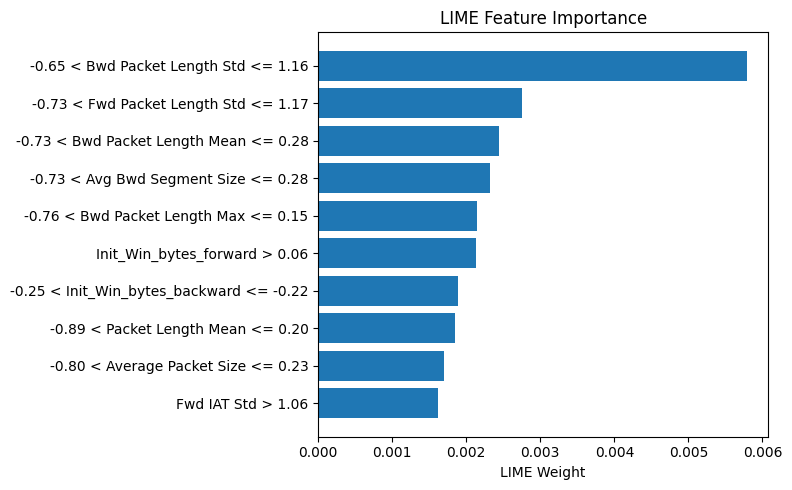

In [57]:
label = lime_exp.top_labels[0]

features = lime_exp.as_list(label=label)

features = features[::-1]

feature_names = [x[0] for x in features]
weights = [x[1] for x in features]

plt.figure(figsize=(8, 5))
plt.barh(feature_names, weights)
plt.xlabel("LIME Weight")
plt.title("LIME Feature Importance")
plt.tight_layout()
save_fig('fig_lime_ftp_patator')
plt.show()

In [ ]:
lime_label = lime_exp.available_labels()[0]
lime_top_features = lime_exp.as_list(label=lime_label)
print(f"LIME explanation for predicted class '{inv_label_map[lime_label]}':")
for feat, weight in lime_top_features:
    print(f"  {feat:45s}  weight={weight:+.4f}")

LIME explanation for predicted class 'FTP-Patator':
  -0.65 < Bwd Packet Length Std <= 1.16          weight=+0.0058
  -0.73 < Fwd Packet Length Std <= 1.17          weight=+0.0027
  -0.73 < Bwd Packet Length Mean <= 0.28         weight=+0.0024
  -0.73 < Avg Bwd Segment Size <= 0.28           weight=+0.0023
  -0.76 < Bwd Packet Length Max <= 0.15          weight=+0.0021
  Init_Win_bytes_forward > 0.06                  weight=+0.0021
  -0.25 < Init_Win_bytes_backward <= -0.22       weight=+0.0019
  -0.89 < Packet Length Mean <= 0.20             weight=+0.0019
  -0.80 < Average Packet Size <= 0.23            weight=+0.0017
  Fwd IAT Std > 1.06                             weight=+0.0016


### 18. Counterfactual Explanation

In [ ]:
def generate_counterfactual(model, instance_df, X_reference, target_class, top_k=10, max_iter=60, step_frac=0.2, recompute_every=5):
    """Greedy counterfactual search: repeatedly nudge the features that differ most from the
    target class's mean, a fraction (step_frac) at a time, until the model's prediction flips
    to target_class (or max_iter is reached).
    Returns: (counterfactual_row, success_flag, n_iterations, confidence_history)"""
    inst = instance_df.copy()
    target_mean = X_reference.mean()
    history = []
    top_feats = None
    for it in range(max_iter):
        cur_pred = model.predict(inst)[0]
        cur_proba = model.predict_proba(inst)[0][target_class]
        history.append(cur_proba)
        if cur_pred == target_class:
            return inst, True, it, history
        if it % recompute_every == 0:
            gap = (target_mean - inst.iloc[0]).abs().sort_values(ascending=False)
            top_feats = gap.index[:top_k]
        for f in top_feats:
            inst.iloc[0, inst.columns.get_loc(f)] += step_frac * (target_mean[f] - inst.iloc[0][f])
    return inst, False, max_iter, history

benign_class_idx = label_map['BENIGN']
benign_reference = X_train_fs[y_train == benign_class_idx]

original_instance = X_test_fs.loc[[idx]]
cf_row, success, n_iter, conf_history = generate_counterfactual(
    model, original_instance, benign_reference, target_class=benign_class_idx
)

print(f"Counterfactual search {'SUCCEEDED' if success else 'did not converge'} in {n_iter} iterations")
print(f"BENIGN-confidence trajectory: {[round(h,3) for h in conf_history[::max(1,len(conf_history)//8)]]}")

changed = (cf_row.iloc[0] - original_instance.iloc[0]).abs().sort_values(ascending=False)
changed = changed[changed > 1e-6].head(8)
print("\nFeatures that had to change for this flow to look BENIGN (largest changes first):")
for feat, delta in changed.items():
    direction = 'increase' if cf_row.iloc[0][feat] > original_instance.iloc[0][feat] else 'decrease'
    print(f"  {feat:35s}  {direction:8s}  (Δ = {delta:.3f}, scaled units)")

Counterfactual search SUCCEEDED in 6 iterations
BENIGN-confidence trajectory: [np.float32(0.0), np.float32(0.009), np.float32(0.01), np.float32(0.034), np.float32(0.022), np.float32(0.018), np.float32(1.0)]

Features that had to change for this flow to look BENIGN (largest changes first):
  Init_Win_bytes_forward               decrease  (Δ = 1.105, scaled units)
  Fwd IAT Std                          decrease  (Δ = 1.050, scaled units)
  Fwd IAT Total                        decrease  (Δ = 0.948, scaled units)
  Fwd IAT Max                          decrease  (Δ = 0.944, scaled units)
  Fwd IAT Mean                         decrease  (Δ = 0.908, scaled units)
  Flow Duration                        decrease  (Δ = 0.755, scaled units)
  Flow IAT Std                         decrease  (Δ = 0.734, scaled units)
  Flow IAT Max                         decrease  (Δ = 0.685, scaled units)


## 19. Evidence → Attack Behavior → Recommended Response

In [ ]:
FEATURE_MEANINGS = {
    'Flow Duration':            'connection duration',
    'Flow IAT Mean':            'time gap between packets (burstiness)',
    'Flow IAT Std':             'irregularity in packet timing',
    'Flow Bytes/s':             'data transfer rate',
    'Flow Packets/s':           'packet transmission rate',
    'Total Fwd Packets':        'number of packets sent to the server',
    'Total Backward Packets':   'number of packets returned by the server',
    'SYN Flag Count':           'connection-initiation (SYN) attempts',
    'RST Flag Count':           'abruptly reset connections',
    'PSH Flag Count':           'forced data-push events',
    'ACK Flag Count':           'acknowledgement packets',
    'Fwd_Bwd_Pkt_Ratio':        'ratio of outgoing to incoming packets',
    'Bytes_per_Packet':         'average payload size per packet',
    'Fwd Packet Length Mean':   'average size of outgoing packets',
    'Bwd Packet Length Mean':   'average size of returned packets',
    'Destination Port':         'target service port',
    'Is_WellKnown_Port':        'whether a standard/well-known port is targeted',
    'Flag_Sum':                 'overall TCP flag activity',
    'Init_Win_bytes_forward':   'initial TCP window size (client side)',
    'Init_Win_bytes_backward':  'initial TCP window size (server side)',
}

def describe_feature(feat_name):
    return FEATURE_MEANINGS.get(feat_name, feat_name.lower())

PORT_SERVICES = {20: 'FTP-data', 21: 'FTP', 22: 'SSH', 23: 'Telnet', 25: 'SMTP', 53: 'DNS', 80: 'HTTP', 110: 'POP3',
                 123: 'NTP', 143: 'IMAP', 443: 'HTTPS', 445: 'SMB', 3306: 'MySQL', 3389: 'RDP', 8080: 'HTTP-alt'}

def build_evidence_statements(top_features_with_direction, instance_row, reference_benign_mean, max_items=4, raw_port=None):
    """top_features_with_direction: list of (feature_name, shap_or_lime_value).
    raw_port: the ORIGINAL (un-scaled) destination port of the flow, used to describe the targeted service."""
    statements = []
    for feat, contribution in top_features_with_direction[:max_items]:
        if feat in ('Destination Port', 'Is_WellKnown_Port') and raw_port is not None:
            port = int(raw_port)
            svc = PORT_SERVICES.get(port, 'non-standard / unlisted service')
            statements.append(f"targets port {port} ({svc}) (feature: {feat})")
            continue
        plain = describe_feature(feat)
        val = instance_row[feat]
        ref = reference_benign_mean.get(feat, np.nan)
        if contribution > 0:
            trend = 'abnormally high' if val > ref else 'abnormally low'
        else:
            trend = 'unusual pattern in'
        statements.append(f"{trend} {plain} (feature: {feat})")
    return statements


In [ ]:
ATTACK_BEHAVIOR = {
    'FTP-Patator':               'Repeated FTP login attempts in rapid succession, consistent with automated credential guessing (brute force).',
    'SSH-Patator':                'Repeated SSH login attempts in rapid succession, consistent with automated credential guessing (brute force).',
    'DoS Hulk':                   'High-volume HTTP requests aimed at exhausting server resources (Denial-of-Service).',
    'DoS GoldenEye':              'HTTP GET/POST flood designed to exhaust server connection pool (Denial-of-Service).',
    'DoS slowloris':              'Slow, partial HTTP requests kept open to exhaust server connection slots (low-and-slow DoS).',
    'DoS Slowhttptest':           'Slow HTTP request/response manipulation to exhaust server resources (low-and-slow DoS).',
    'DDoS':                       'Coordinated high-volume traffic from the flow pattern, consistent with a distributed denial-of-service attack.',
    'PortScan':                   'Sequential probing of multiple destination ports from the same source, consistent with reconnaissance/port scanning.',
    'Bot':                        'Periodic, automated command-and-control-like traffic pattern, consistent with botnet activity.',
    'Infiltration':               'Anomalous internal traffic pattern following an initial foothold, consistent with lateral movement / infiltration.',
    'Web Attack - Brute Force':   'Repeated web-login attempts, consistent with credential brute forcing against a web application.',
    'Web Attack - XSS':           'Malformed/scripted payload pattern in web requests, consistent with cross-site scripting attempts.',
    'Web Attack - Sql Injection': 'Malformed query-like payload pattern in web requests, consistent with SQL injection attempts.',
    'Heartbleed':                 'Abnormal TLS heartbeat response pattern, consistent with the Heartbleed information-disclosure exploit.',
    'BENIGN':                     'Traffic pattern consistent with normal, legitimate usage.',
}

RECOMMENDED_RESPONSE = {
    'FTP-Patator':                'Lock/rate-limit the source IP; enforce account lockout after N failed attempts; enable MFA on FTP service.',
    'SSH-Patator':                'Rate-limit or temporarily block the source IP; enforce key-based SSH auth; enable fail2ban-style protection.',
    'DoS Hulk':                   'Enable rate-limiting/WAF rules for the target service; scale resources or activate DDoS-mitigation.',
    'DoS GoldenEye':              'Enable connection-rate limiting and WAF rules; monitor server connection pool.',
    'DoS slowloris':              'Configure server timeout limits for slow connections; deploy a reverse-proxy with slow-request protection.',
    'DoS Slowhttptest':           'Configure server timeout limits for slow connections; deploy a reverse-proxy with slow-request protection.',
    'DDoS':                       'Engage upstream DDoS mitigation/scrubbing; rate-limit at the edge; alert network operations team immediately.',
    'PortScan':                   'Flag source IP for monitoring; ensure unused ports are closed; review firewall rules.',
    'Bot':                        'Isolate the host for forensic review; block C2-suspected destinations; run malware scan on the host.',
    'Infiltration':               'Escalate to incident response immediately; isolate affected host; audit lateral-movement paths.',
    'Web Attack - Brute Force':   'Enable account lockout / CAPTCHA on login; rate-limit the source IP; enforce MFA.',
    'Web Attack - XSS':           'Sanitize/validate input on the affected endpoint; deploy/tune WAF XSS rules; review recent submissions from this source.',
    'Web Attack - Sql Injection': 'Sanitize/parameterize queries on the affected endpoint; deploy/tune WAF SQLi rules; audit database access logs.',
    'Heartbleed':                 'Patch/upgrade the affected OpenSSL version immediately; rotate certificates and secrets; audit for prior exploitation.',
    'BENIGN':                     'No action needed — continue routine monitoring.',
}
print("Behavior + response templates ready for", len(ATTACK_BEHAVIOR), "classes.")

Behavior + response templates ready for 15 classes.


In [65]:
def xthreat_report(instance_index, model, X_pool, shap_values_pool, shap_index_map,
                    explainer, benign_reference_mean, label_map, inv_label_map, run_counterfactual=True):
    row = X_pool.loc[[instance_index]]
    pred_class = model.predict(row)[0]
    pred_label = inv_label_map[pred_class]
    confidence = model.predict_proba(row).max()
    print("="*70)
    print(f"  ATTACK DETECTED: {pred_label}")
    print("="*70)
    if pred_label == 'BENIGN':
        print("No further explanation needed — this flow is classified as normal traffic.")
        print(f"Confidence: {confidence:.2%}")
        return
    pos = shap_index_map[instance_index]
    sv_row = get_class_shap_row(shap_values_pool, pos, pred_class)
    feat_importance = pd.Series(sv_row, index=X_pool.columns).sort_values(key=np.abs, ascending=False)
    top_features = list(feat_importance.head(4).items())
    print("\n Evidence (top contributing features, SHAP):")
    raw_port = df.loc[instance_index, 'Destination Port'] if ('Destination Port' in df.columns and instance_index in df.index) else None
    evidence = build_evidence_statements(top_features, row.iloc[0], benign_reference_mean, raw_port=raw_port)
    for e in evidence:
        print(f"  - {e}")

    print("\nImportant features (ranked by |SHAP value|):")
    for feat, val in top_features:
        print(f"  - {feat}: SHAP={val:+.4f}")

    print(f"\nAttack behavior:\n  {ATTACK_BEHAVIOR.get(pred_label, 'No template defined for this class yet.')}")

    print(f"\nConfidence: {confidence:.2%}")

    print(f"\nRecommended response:\n  {RECOMMENDED_RESPONSE.get(pred_label, 'No template defined for this class yet.')}")

    if run_counterfactual:
        benign_class_idx = label_map['BENIGN']
        benign_ref = X_train_fs[y_train == benign_class_idx]
        cf_row, success, n_iter, _ = generate_counterfactual(model, row, benign_ref, target_class=benign_class_idx, max_iter=40)
        if success:
            changed = (cf_row.iloc[0] - row.iloc[0]).abs().sort_values(ascending=False).head(3)
            print(f"\nCounterfactual (what would make this look BENIGN):")
            for feat, delta in changed.items():
                direction = 'increase' if cf_row.iloc[0][feat] > row.iloc[0][feat] else 'decrease'
                print(f"  - {direction} {describe_feature(feat)} (feature: {feat})")
    print("="*70)


shap_index_map = {sample_idx[i]: i for i in range(len(sample_idx))}
benign_reference_mean = X_train_fs[y_train == label_map['BENIGN']].mean()

demo_targets = [idx] 
other_attack_idx = X_shap_sample.index[(model.predict(X_shap_sample) != label_map['BENIGN']) & (X_shap_sample.index != idx)]
if len(other_attack_idx) > 0:
    demo_targets.append(other_attack_idx[0])

for t in demo_targets:
    xthreat_report(t, model, X_shap_sample, shap_values, shap_index_map, explainer, benign_reference_mean, label_map, inv_label_map)
    print()

  ATTACK DETECTED: FTP-Patator

 Evidence (top contributing features, SHAP):
  - targets port 21 (FTP) (feature: Destination Port)
  - abnormally low avg fwd segment size (feature: Avg Fwd Segment Size)
  - abnormally low data transfer rate (feature: Flow Bytes/s)
  - abnormally high total length of bwd packets (feature: Total Length of Bwd Packets)

Important features (ranked by |SHAP value|):
  - Destination Port: SHAP=+14.7437
  - Avg Fwd Segment Size: SHAP=+0.9500
  - Flow Bytes/s: SHAP=+0.8294
  - Total Length of Bwd Packets: SHAP=+0.7570

Attack behavior:
  Repeated FTP login attempts in rapid succession, consistent with automated credential guessing (brute force).

Confidence: 100.00%

Recommended response:
  Lock/rate-limit the source IP; enforce account lockout after N failed attempts; enable MFA on FTP service.

Counterfactual (what would make this look BENIGN):
  - decrease initial TCP window size (client side) (feature: Init_Win_bytes_forward)
  - decrease fwd iat std (feat

## 20. Quantitative evaluation of the explanations

Evaluating explanations on 29 predicted-attack flows from 11 classes
                          overlap_at5  sign_agreement  top1_agree
cls                                                              
Bot                             0.200           0.833       0.000
DDoS                            0.067           1.000       0.000
DoS GoldenEye                   0.400           1.000       0.000
DoS Hulk                        0.467           1.000       0.667
DoS Slowhttptest                0.400           1.000       0.000
DoS slowloris                   0.200           0.833       0.000
FTP-Patator                     0.133           0.750       0.000
PortScan                        0.400           1.000       0.333
SSH-Patator                     0.500           0.800       0.500
Web Attack - Brute Force        0.267           0.778       0.000
Web Attack - XSS                0.600           0.750       0.000
{'n': 29, 'overlap_at5_mean': 0.31034482758620685, 'sign_agreement_mean':

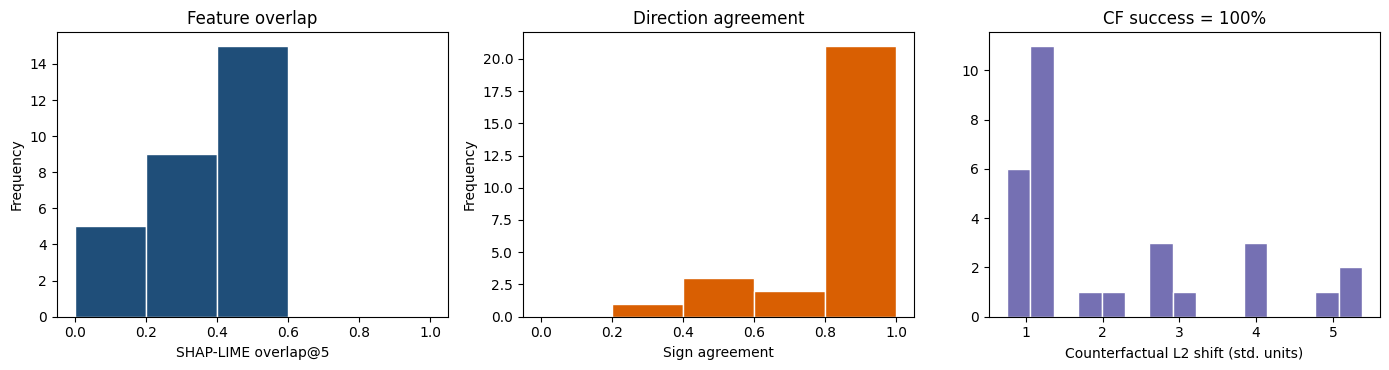

In [ ]:
rs = np.random.RandomState(RANDOM_STATE)
pred_sample = model.predict(X_shap_sample)
attack_pos = np.where(pred_sample != label_map['BENIGN'])[0]
chosen = []
for c in np.unique(pred_sample[attack_pos]):
    pos_c = attack_pos[pred_sample[attack_pos] == c]
    chosen.extend(rs.choice(pos_c, size=min(3, len(pos_c)), replace=False).tolist())
print(f"Evaluating explanations on {len(chosen)} predicted-attack flows from {len(np.unique(pred_sample[attack_pos]))} classes")

TOPK = 5
agree_rows = []
for pos in chosen:
    c = int(pred_sample[pos])
    sv = shap_arr[pos, :, c]
    shap_top = np.argsort(-np.abs(sv))[:TOPK]
    exp_i = lime_explainer.explain_instance(X_shap_sample.iloc[pos].values, model.predict_proba,
                                            num_features=10, labels=(c,), num_samples=2000)
    lw = dict(exp_i.as_map()[c])                                   # {feature index: LIME weight}
    lime_top = sorted(lw, key=lambda j: -abs(lw[j]))[:TOPK]
    common = [j for j in shap_top if j in lw]
    agree_rows.append(dict(cls=inv_label_map[c],
                           overlap_at5=len(set(shap_top) & set(lime_top)) / TOPK,
                           sign_agreement=float(np.mean([np.sign(sv[j]) == np.sign(lw[j]) for j in common])) if common else np.nan,
                           top1_agree=bool(shap_top[0] == lime_top[0])))
agree = pd.DataFrame(agree_rows)
print(agree.groupby('cls')[['overlap_at5', 'sign_agreement', 'top1_agree']].mean().round(3))
summary_agree = dict(n=len(agree), overlap_at5_mean=float(agree['overlap_at5'].mean()),
                     sign_agreement_mean=float(agree['sign_agreement'].mean()), top1_agreement_rate=float(agree['top1_agree'].mean()))
print(summary_agree)
RESULTS['shap_lime_agreement'] = summary_agree
agree.to_csv(os.path.join(FIG_DIR, 'shap_lime_agreement.csv'), index=False)

benign_ref = X_train_fs[y_train == label_map['BENIGN']]
cf_rows = []
for pos in chosen:
    row = X_shap_sample.iloc[[pos]]
    cf, ok, n_it, hist = generate_counterfactual(model, row, benign_ref, target_class=label_map['BENIGN'], max_iter=60)
    delta = cf.iloc[0] - row.iloc[0]
    cf_rows.append(dict(cls=inv_label_map[int(pred_sample[pos])], success=bool(ok), iterations=int(n_it),
                        l2=float(np.linalg.norm(delta.values)), final_benign_prob=float(hist[-1])))
cfs = pd.DataFrame(cf_rows)
print(cfs.groupby('cls')[['success', 'iterations', 'l2']].mean().round(3))
summary_cf = dict(success_rate=float(cfs['success'].mean()), median_iterations=float(cfs['iterations'].median()),
                  median_l2=float(cfs['l2'].median()))
print(summary_cf)
RESULTS['counterfactual'] = summary_cf
cfs.to_csv(os.path.join(FIG_DIR, 'counterfactual_stats.csv'), index=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
agree['overlap_at5'].plot.hist(bins=np.linspace(0, 1, 6), ax=ax[0], color='#1f4e79', edgecolor='white'); ax[0].set_xlabel('SHAP-LIME overlap@5'); ax[0].set_title('Feature overlap')
agree['sign_agreement'].dropna().plot.hist(bins=np.linspace(0, 1, 6), ax=ax[1], color='#d95f02', edgecolor='white'); ax[1].set_xlabel('Sign agreement'); ax[1].set_title('Direction agreement')
ax[2].hist(cfs['l2'], bins=15, color='#7570b3', edgecolor='white'); ax[2].set_xlabel('Counterfactual L2 shift (std. units)'); ax[2].set_title(f"CF success = {summary_cf['success_rate']:.0%}")
plt.tight_layout(); save_fig('fig_explanation_evaluation'); plt.show()

In [ ]:
import json
def _js(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
RESULTS['xgb_per_class'] = classification_report(y_test, y_pred, target_names=target_names, digits=4, zero_division=0, output_dict=True)
RESULTS['lgbm_per_class'] = classification_report(y_test, y_pred_lgbm, target_names=target_names, digits=4, zero_division=0, output_dict=True)
RESULTS['macro_roc_auc_ovr_xgb'] = float(roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'))
with open(os.path.join(FIG_DIR, 'results_summary.json'), 'w') as f:
    json.dump(RESULTS, f, indent=2, default=_js)
print("Saved:", sorted(os.listdir(FIG_DIR)))

Saved: ['ablation_port.csv', 'confusion_matrix_counts_xgb.csv', 'counterfactual_stats.csv', 'fig_binary_roc_pr.pdf', 'fig_binary_roc_pr.png', 'fig_class_distribution_raw.pdf', 'fig_class_distribution_raw.png', 'fig_class_distribution_resampling.pdf', 'fig_class_distribution_resampling.png', 'fig_confusion_matrix_xgb.pdf', 'fig_confusion_matrix_xgb.png', 'fig_explanation_evaluation.pdf', 'fig_explanation_evaluation.png', 'fig_key_feature_distributions.pdf', 'fig_key_feature_distributions.png', 'fig_learning_curve.pdf', 'fig_learning_curve.png', 'fig_lime_ftp_patator.pdf', 'fig_lime_ftp_patator.png', 'fig_per_class_f1_heatmap.pdf', 'fig_per_class_f1_heatmap.png', 'fig_port_ablation.pdf', 'fig_port_ablation.png', 'fig_random_vs_chronological.pdf', 'fig_random_vs_chronological.png', 'fig_selected_feature_correlation.pdf', 'fig_selected_feature_correlation.png', 'fig_shap_global_predicted_class.pdf', 'fig_shap_global_predicted_class.png', 'fig_shap_global_stacked.pdf', 'fig_shap_global_stac